# Diffusion Model

## 0. Imports & Setup

In [1]:
import os
import gc
import math
import random

import numpy as np
import pandas as pd
import xarray as xr

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
def set_seed(seed):
    """
    Use this to set ALL the random seeds to a fixed value and take out any randomness from cuda kernels
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False  # uses the inbuilt cudnn auto-tuner to find the fastest convolution algorithms
    torch.backends.cudnn.enabled   = False

    return True

In [3]:
# Detect HPC vs local
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

# Derived paths
DATA_ROOT           = os.path.join(ROOT, "data")
CMIP6_SAVE_DIR      = os.path.join(DATA_ROOT, "processed", "cmip6")
INPUT4MIPS_SAVE_DIR = os.path.join(DATA_ROOT, "processed", "input4mips")
FIGURES_DIR         = os.path.join(ROOT, "figures")
CHECKPOINT_DIR      = os.path.join(ROOT, "checkpoints")

# create write dirs if don't exist
for dir_paths in [FIGURES_DIR, CHECKPOINT_DIR]:
    if not os.path.exists(dir_paths):
        os.makedirs(dir_paths, exist_ok=True)

best_model_path = os.path.join(CHECKPOINT_DIR, "diffusion_best.pt")
last_model_path = os.path.join(CHECKPOINT_DIR, "diffusion_last.pt")

N_EPOCHS = 20 if IS_HPC else 2
SAVE_EVERY = 1

# choose one:
# "train"  -> always train from scratch
# "resume" -> resume from last checkpoint if it exists, ow train from scratch
# "eval"   -> skip training and load best checkpoint only
RUN_MODE = "resume"
assert RUN_MODE in {"train", "resume", "eval"}

print(f"Running on: {'HPC' if IS_HPC else 'local'}")
print(f"Root:            {ROOT}")
print(f"Data root:       {DATA_ROOT}")
print(f"CMIP6:           {CMIP6_SAVE_DIR}")
print(f"Input4MIPS:      {INPUT4MIPS_SAVE_DIR}")
print(f"Figures:         {FIGURES_DIR}")
print(f"Checkpoints:     {CHECKPOINT_DIR}")
print(f"\nRUN_MODE = {RUN_MODE}")
print(f"Best checkpoint exists: {os.path.exists(best_model_path)}")
print(f"Last checkpoint exists: {os.path.exists(last_model_path)}")

Using device: cpu
Running on: HPC
Root:            /rds/general/user/efs25/home/irp-efs25
Data root:       /rds/general/user/efs25/home/irp-efs25/data
CMIP6:           /rds/general/user/efs25/home/irp-efs25/data/processed/cmip6
Input4MIPS:      /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips
Figures:         /rds/general/user/efs25/home/irp-efs25/figures
Checkpoints:     /rds/general/user/efs25/home/irp-efs25/checkpoints

RUN_MODE = resume
Best checkpoint exists: True
Last checkpoint exists: True


### Load CMIP6 and INPUT4MIPS Zarrs

In [4]:
# if HPC load all cmip models and input4mips atm co2
# if local, load only cesm2 and atm co2

ALL_MODELS = ["CESM2", "CanESM5", "CanESM5-CanOE", "GFDL-ESM4", "UKESM1-0-LL"]
MODELS_TO_LOAD = ALL_MODELS if IS_HPC else ["CESM2"]

datasets = {}
for model_name in MODELS_TO_LOAD:
    model_path = os.path.join(CMIP6_SAVE_DIR, f"{model_name}.zarr")
    if os.path.exists(model_path):
        datasets[model_name] = xr.open_zarr(model_path)
        print(f"Loaded {model_name}")
    else:
        print(f"  {model_name} not found at {model_path} - skipping")

# load atmospheric CO2
CO2_PATH = os.path.join(INPUT4MIPS_SAVE_DIR, "atmCO2_1850_2100_regridded.zarr")
ds_co2 = xr.open_zarr(CO2_PATH)
print("\nLoaded atmospheric CO2")
print(f"Variables: {list(ds_co2.data_vars)}")

# keep a single reference dataset for the input-stack-building code below
CMIP_MODEL_NAME = MODELS_TO_LOAD[0]
ds = datasets[CMIP_MODEL_NAME]

print(f"\nUsing {CMIP_MODEL_NAME} for pipeline build")
print(f"Variables: {list(ds.data_vars)}")
print(f"Dims: {dict(ds.sizes)}")

Loaded CESM2
Loaded CanESM5
Loaded CanESM5-CanOE
Loaded GFDL-ESM4


Loaded UKESM1-0-LL

Loaded atmospheric CO2
Variables: ['lat_bnds', 'mole_fraction_of_carbon_dioxide_in_air', 'time_bnds']

Using CESM2 for pipeline build
Variables: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'pco2_residual', 'pco2_thermal', 'sos', 'sos_anom', 'spco2', 'tos', 'tos_anom']
Dims: {'time': 3012, 'lat': 180, 'lon': 360}


### Train/test split by CMIP6 model (leave one model out)

In [5]:
TEST_MODEL = "UKESM1-0-LL"
TRAIN_MODELS = [m for m in ALL_MODELS if m != TEST_MODEL]

assert TEST_MODEL in datasets, f"{TEST_MODEL} not loaded, cannot hold it out for testing."
TRAIN_MODELS = [m for m in TRAIN_MODELS if m in datasets]

print(f"Train models ({len(TRAIN_MODELS)}): {TRAIN_MODELS}")
print(f"Test model: {TEST_MODEL}")

train_datasets = {m: datasets[m] for m in TRAIN_MODELS}
test_dataset = datasets[TEST_MODEL]

Train models (4): ['CESM2', 'CanESM5', 'CanESM5-CanOE', 'GFDL-ESM4']
Test model: UKESM1-0-LL


### Chronological train/validation split within training models

In [6]:
TRAIN_FRAC = 0.8

def chronological_split(ds, train_frac=TRAIN_FRAC):
    n_time = ds.sizes["time"]
    split_idx = int(n_time * train_frac)
    ds_train = ds.isel(time=slice(0, split_idx))
    ds_val = ds.isel(time=slice(split_idx, n_time))
    return ds_train, ds_val

train_split_datasets = {}
val_split_datasets = {}

for model_name, model_ds in train_datasets.items():
    ds_tr, ds_val = chronological_split(model_ds)
    train_split_datasets[model_name] = ds_tr
    val_split_datasets[model_name] = ds_val
    print(f"{model_name}: train {ds_tr.sizes['time']} months, val {ds_val.sizes['time']} months")

CESM2: train 2409 months, val 603 months
CanESM5: train 2409 months, val 603 months


CanESM5-CanOE: train 2409 months, val 603 months
GFDL-ESM4: train 2409 months, val 603 months


## Input Stack

### Define covariates and target variables

In [7]:
# Covariates
COVARIATE_VARS = [
    "tos", "tos_anom",
    "sos", "sos_anom",
    "chlos", "chlos_anom",
    "mlotst", "mlotst_anom",
]

# Target
TARGET_VAR = "pco2_residual"

print(f"Covariates from CMIP6 ({len(COVARIATE_VARS)} channels): {COVARIATE_VARS}")
print("+ atmospheric CO2 (1 channel) from input4mips")
print(f"Target: {TARGET_VAR}")

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")

# will add monthly encodings if needed

Covariates from CMIP6 (8 channels): ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom']
+ atmospheric CO2 (1 channel) from input4mips
Target: pco2_residual
ds.time dtype: <class 'cftime._cftime.DatetimeNoLeap'>
ds_co2.time dtype: <class 'numpy.datetime64'>


### Add atmospheric CO2 from input4mips

In [8]:
co2_var = "mole_fraction_of_carbon_dioxide_in_air"

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")
# different, need match!

def to_year_month_cftime(time_values):
    """For cftime objects (CMIP6 model time) - .year/.month work directly."""
    return [(t.year, t.month) for t in time_values]

def to_year_month_numpy(time_values):
    """For numpy.datetime64 (CO2 dataset time) - convert via pandas Timestamp."""
    return [(pd.Timestamp(t).year, pd.Timestamp(t).month) for t in time_values]

ds_ym  = to_year_month_cftime(ds.time.values)
co2_ym = to_year_month_numpy(ds_co2.time.values)

co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

# check for any missing matches before indexing
missing = [ym for ym in ds_ym if ym not in co2_lookup]
if missing:
    print(f"WARNING: {len(missing)} CMIP6 timesteps have no matching CO2 month")
    print(f"First few missing: {missing[:5]}")
else:
    print("All CMIP6 timesteps found a matching CO2 month.")

co2_indices = [co2_lookup[ym] for ym in ds_ym]

co2_data = ds_co2[co2_var]
print(f"Before dropping bounds: {co2_data.dims}")

# select index 0 along bound/bnds dims to collapse them
if "bound" in co2_data.dims:
    co2_data = co2_data.isel(bound=0, drop=True)
if "bnds" in co2_data.dims:
    co2_data = co2_data.isel(bnds=0, drop=True)

print(f"After dropping bounds: {co2_data.dims}")
print(f"Shape: {co2_data.shape}")

co2_indices = [co2_lookup[ym] for ym in ds_ym]

# now align to CMIP6 time using isel
co2_aligned_da = co2_data.isel(time=co2_indices)
print(f"\nCO2 aligned dims: {co2_aligned_da.dims}")
print(f"CO2 aligned shape: {co2_aligned_da.shape}")

# co2_aligned_values = co2_aligned_da.values
co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values # to match cmip order
print(f"CO2 sample value: {co2_aligned_values[0].mean():.2f} ppm")

ds.time dtype: <class 'cftime._cftime.DatetimeNoLeap'>
ds_co2.time dtype: <class 'numpy.datetime64'>
All CMIP6 timesteps found a matching CO2 month.
Before dropping bounds: ('lon', 'lat', 'time', 'bound', 'bnds')
After dropping bounds: ('lon', 'lat', 'time')
Shape: (360, 180, 3012)

CO2 aligned dims: ('lon', 'lat', 'time')
CO2 aligned shape: (360, 180, 3012)


CO2 sample value: 285.22 ppm


### Build the input stack tensor

We stack the covariates along a new "channel" dimension with shape (time, channel, lat, lon)

In [9]:
def build_input_target_stack(ds, dsco2, COVARIATE_VARS, TARGET_VAR):
    """
    Runs the CO2 alignment + covariate stacking logic for a single model's dataset.
    Returns (input_stack, target_stack) with shapes (time, channel, lat, lon) / (time, 1, lat, lon).
    """

    print("Building input stack...")

    co2var = "mole_fraction_of_carbon_dioxide_in_air"

    def to_year_month_cftime(time_values):
        return [(t.year, t.month) for t in time_values]

    def to_year_month_numpy(time_values):
        return [(pd.Timestamp(t).year, pd.Timestamp(t).month) for t in time_values]

    ds_ym = to_year_month_cftime(ds.time.values)
    co2_ym = to_year_month_numpy(dsco2.time.values)
    co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

    missing = [ym for ym in ds_ym if ym not in co2_lookup]
    if missing:
        raise ValueError(f"{len(missing)} timesteps have no matching CO2 month: {missing[:5]}")

    co2_indices = [co2_lookup[ym] for ym in ds_ym]
    co2_data = dsco2[co2var]
    if "bound" in co2_data.dims:
        co2_data = co2_data.isel(bound=0, drop=True)
    if "bnds" in co2_data.dims:
        co2_data = co2_data.isel(bnds=0, drop=True)

    co2_aligned_da = co2_data.isel(time=co2_indices)
    co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values.astype(np.float32) # float 32

    covariate_arrays = [ds[var].values.astype(np.float32) for var in COVARIATE_VARS] # float 32
    all_arrays = covariate_arrays + [co2_aligned_values]
    input_stack = np.stack(all_arrays, axis=1).astype(np.float32)  # (time, channel, lat, lon) - float 32
    target_stack = ds[TARGET_VAR].values[:, np.newaxis].astype(np.float32) # float 32

    ALL_COVARIATE_NAMES = COVARIATE_VARS + ["co2_atm"]

    print(f"   Input stack shape:  {input_stack.shape}")
    print(f"   Target stack shape: {target_stack.shape}")
    print(f"   Channels: {ALL_COVARIATE_NAMES}")
    print(f"   Input NaN fraction:  {np.isnan(input_stack).mean():.3f}")
    print(f"   Target NaN fraction: {np.isnan(target_stack).mean():.3f}")

    return input_stack, target_stack

In [10]:
print("Building input stacks for train, val, test...")

train_inputs, train_targets = [], []
for model_name, model_ds in train_split_datasets.items():
    print(f"  TRAIN stack: {model_name}")
    x, y = build_input_target_stack(model_ds, ds_co2, COVARIATE_VARS, TARGET_VAR)
    train_inputs.append(x)
    train_targets.append(y)

val_inputs, val_targets = [], []
for model_name, model_ds in val_split_datasets.items():
    print(f"  VAL stack: {model_name}")
    x, y = build_input_target_stack(model_ds, ds_co2, COVARIATE_VARS, TARGET_VAR)
    val_inputs.append(x)
    val_targets.append(y)

print(f"  TEST stack: {TEST_MODEL}")
test_input_stack, test_target_stack = build_input_target_stack(test_dataset, ds_co2, COVARIATE_VARS, TARGET_VAR)

train_input_stack = np.concatenate(train_inputs, axis=0)
train_target_stack = np.concatenate(train_targets, axis=0)
val_input_stack = np.concatenate(val_inputs, axis=0)
val_target_stack = np.concatenate(val_targets, axis=0)

# rmv raw per-model lists from memory
del train_inputs, train_targets, val_inputs, val_targets 
gc.collect()

ALL_COVARIATE_NAMES = COVARIATE_VARS + ["co2_atm"]

print(f"Train input stack shape: {train_input_stack.shape}")
print(f"Val input stack shape:   {val_input_stack.shape}")
print(f"Test input stack shape:  {test_input_stack.shape}")
print(f"Channels: {ALL_COVARIATE_NAMES}")

Building input stacks for train, val, test...
  TRAIN stack: CESM2
Building input stack...


   Input stack shape:  (2409, 9, 180, 360)
   Target stack shape: (2409, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm']


   Input NaN fraction:  0.399
   Target NaN fraction: 0.449
  TRAIN stack: CanESM5
Building input stack...


   Input stack shape:  (2409, 9, 180, 360)
   Target stack shape: (2409, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm']


   Input NaN fraction:  0.322
   Target NaN fraction: 0.362
  TRAIN stack: CanESM5-CanOE
Building input stack...


...

   Input stack shape:  (603, 9, 180, 360)
   Target stack shape: (603, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm']


   Input NaN fraction:  0.283
   Target NaN fraction: 0.319
  TEST stack: UKESM1-0-LL
Building input stack...


   Input stack shape:  (3012, 9, 180, 360)
   Target stack shape: (3012, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm']


   Input NaN fraction:  0.322
   Target NaN fraction: 0.362


Train input stack shape: (9636, 9, 180, 360)
Val input stack shape:   (2412, 9, 180, 360)
Test input stack shape:  (3012, 9, 180, 360)
Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'co2_atm']


### Replace NaNs (land cells) with 0 and track a land mask

In [11]:
# train_land_mask = np.isnan(train_target_stack)
# val_land_mask = np.isnan(val_target_stack)
# test_land_mask = np.isnan(test_target_stack)

def build_combined_mask(input_stack, target_stack):
    """
    Combines NaN locations across all input channels and the target into a single
    (time, 1, lat, lon) land/invalid mask. A cell is masked if ANY channel (including
    target) is NaN there, so covariate-only NaNs can't leak into training as fake zeros.
    """
    input_nan_any = np.isnan(input_stack).any(axis=1, keepdims=True)  # (time, 1, lat, lon)
    target_nan = np.isnan(target_stack)  # (time, 1, lat, lon)
    return input_nan_any | target_nan

train_land_mask = build_combined_mask(train_input_stack, train_target_stack)
val_land_mask = build_combined_mask(val_input_stack, val_target_stack)
test_land_mask = build_combined_mask(test_input_stack, test_target_stack)

# mutate in place
np.nan_to_num(train_input_stack, copy=False, nan=0.0)
np.nan_to_num(train_target_stack, copy=False, nan=0.0)
np.nan_to_num(val_input_stack, copy=False, nan=0.0)
np.nan_to_num(val_target_stack, copy=False, nan=0.0)
np.nan_to_num(test_input_stack, copy=False, nan=0.0)
np.nan_to_num(test_target_stack, copy=False, nan=0.0)

train_input_clean = train_input_stack
train_target_clean = train_target_stack
val_input_clean = val_input_stack
val_target_clean = val_target_stack
test_input_clean = test_input_stack
test_target_clean = test_target_stack

print(f"Train land mask fraction: {train_land_mask.mean():.3f}")
print(f"Val land mask fraction: {val_land_mask.mean():.3f}")
print(f"Test land mask fraction: {test_land_mask.mean():.3f}")

# sanity check: per-channel NaN fraction vs combined mask fraction
per_channel_nan_frac = np.isnan(train_input_stack).mean(axis=(0, 2, 3))
print(f"Per-channel NaN fraction (train input): {per_channel_nan_frac}")
print(f"Target-only NaN fraction (train): {np.isnan(train_target_stack).mean():.3f}")
print(f"Combined mask fraction (train): {train_land_mask.mean():.3f}")

Train land mask fraction: 0.373
Val land mask fraction: 0.373
Test land mask fraction: 0.363


Per-channel NaN fraction (train input): [0. 0. 0. 0. 0. 0. 0. 0. 0.]


Target-only NaN fraction (train): 0.000


Combined mask fraction (train): 0.373


## Normalise (0 mean, 1 variance per channel)

For stable training and reducing CMIP6/satellite covariate distribution mismatch

In [12]:
def apply_normalisation(stack, means, stds):
    """ In-place normalisation"""
    for c in range(stack.shape[1]):
        stack[:, c] -= means[c]
        stack[:, c] /= (stds[c] + 1e-8)
    return stack

def normalise_stack(stack, mask):
    """
    Computes per-channel mean/std over ocean cells only (mask marks land/NaN cells to exclude),
    then applies normalisation. Returns (normalized_stack, means, stds).
    """
    n_channels = stack.shape[1]
    means = np.zeros(n_channels, dtype=np.float32)
    stds = np.zeros(n_channels, dtype=np.float32)

    ocean_mask = ~mask  # mask is True over land; invert to get valid ocean cells
    # mask has shape (time, 1, lat, lon) - broadcast against each channel
    ocean_mask_b = np.broadcast_to(ocean_mask, stack.shape)

    for c in range(n_channels):
        valid_vals = stack[:, c][ocean_mask_b[:, c]]
        means[c] = valid_vals.mean()
        stds[c] = valid_vals.std()

    apply_normalisation(stack, means, stds) # no copy
    return stack, means, stds

train_input_norm, input_means, input_stds = normalise_stack(train_input_clean, mask=train_land_mask)
train_target_norm, target_means, target_stds = normalise_stack(train_target_clean, mask=train_land_mask)

val_input_norm = apply_normalisation(val_input_clean, input_means, input_stds)
val_target_norm = apply_normalisation(val_target_clean, target_means, target_stds)

test_input_norm = apply_normalisation(test_input_clean, input_means, input_stds)
test_target_norm = apply_normalisation(test_target_clean, target_means, target_stds)

print(f"Input means (from TRAIN only): {input_means}")
print(f"Target mean: {target_means[0]:.2f}, std: {target_stds[0]:.2f}")

Input means (from TRAIN only): [ 1.4182772e+01 -3.3067638e-01  3.4029617e+01  2.4914626e-02
  2.5053939e-01  1.3416399e-03  5.7786015e+01  8.4969848e-01
  3.4014410e+02]
Target mean: -39.94, std: 53.54


### Convert to PyTorch tensors

In [13]:
assert train_input_norm.dtype == np.float32 # so no need to call .float() on all below
train_input_tensor = torch.from_numpy(train_input_norm)
train_target_tensor = torch.from_numpy(train_target_norm)
val_input_tensor = torch.from_numpy(val_input_norm)
val_target_tensor = torch.from_numpy(val_target_norm)
test_input_tensor = torch.from_numpy(test_input_norm)
test_target_tensor = torch.from_numpy(test_target_norm)

print(f"Train tensor: {train_input_tensor.shape}")
print(f"Val tensor:   {val_input_tensor.shape}")
print(f"Test tensor:  {test_input_tensor.shape}")

BATCH_SIZE = 32 if IS_HPC else 4
batch_idx = torch.randperm(train_input_tensor.shape[0])[:BATCH_SIZE]
input_batch = train_input_tensor[batch_idx].to(DEVICE)
target_batch = train_target_tensor[batch_idx].to(DEVICE)
land_mask_batch = torch.from_numpy(train_land_mask[batch_idx]).bool().to(DEVICE)

print("Batch size = ", BATCH_SIZE)
print(f"Batch shapes - input: {input_batch.shape}, target: {target_batch.shape}")

Train tensor: torch.Size([9636, 9, 180, 360])
Val tensor:   torch.Size([2412, 9, 180, 360])
Test tensor:  torch.Size([3012, 9, 180, 360])
Batch size =  32
Batch shapes - input: torch.Size([32, 9, 180, 360]), target: torch.Size([32, 1, 180, 360])


## Diffusion Model
Code inspired from Deep Learning Day 09 lecture notebooks.

In [14]:
def cosine_beta_schedule(T, s=0.008):
    steps = T + 1
    x = torch.linspace(0, T, steps)
    alphas_cumprod = torch.cos(((x / T) + s) / (1 + s) * torch.pi * 0.5) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return torch.clip(betas, 0.0001, 0.9999)

T = 1000 # steps
betas = cosine_beta_schedule(T).to(DEVICE)
alphas = 1. - betas
alphas_bar = torch.cumprod(alphas, dim=0)

def fix_batch(vals, t, device):
    out = vals.gather(-1, t.to(device))
    return out.reshape(-1, 1, 1, 1).to(device)

In [15]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

### Forward Pass

In [16]:
def forward_diffusion(x0, t, e):
    sqrt_alphas = fix_batch(torch.sqrt(alphas_bar), t, x0.device)
    sqrt_alphas_minus_one = fix_batch(torch.sqrt(1. - alphas_bar), t, x0.device)
    return sqrt_alphas * x0 + sqrt_alphas_minus_one * e

### Conditional U-Net

In [17]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, embed_dim):
        super().__init__()
        self.conv = nn.Conv2d(in_c, out_c, kernel_size=3, padding=1)
        self.bn = nn.BatchNorm2d(out_c)
        self.act = nn.GELU()
        self.embed_proj = nn.Linear(embed_dim, out_c)

    def forward(self, x, t_embed):
        x = self.conv(x)
        x = x + self.embed_proj(t_embed)[:, :, None, None]
        x = self.bn(x)
        x = self.act(x)
        return x

class EncBlock(nn.Module):
    def __init__(self, in_c, out_c, embed_dim):
        super().__init__()
        self.conv_block1 = ConvBlock(in_c, out_c, embed_dim)
        self.conv_block2 = ConvBlock(out_c, out_c, embed_dim)
        self.pool = nn.MaxPool2d((2, 2))

    def forward(self, x, t_embed):
        h = self.conv_block1(x, t_embed)
        h = self.conv_block2(h, t_embed)
        p = self.pool(h)
        return h, p

class DecBlock(nn.Module):
    def __init__(self, in_c, out_c, embed_dim):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_c, out_c, kernel_size=2, stride=2, padding=0)
        self.conv_block1 = ConvBlock(out_c + out_c, out_c, embed_dim)
        self.conv_block2 = ConvBlock(out_c, out_c, embed_dim)

    def forward(self, x, s, t_embed):
        h = self.up(x)
        h = torch.cat([h, s], axis=1)
        h = self.conv_block1(h, t_embed)
        h = self.conv_block2(h, t_embed)
        return h

class ConditionalUnet(nn.Module):
    """
    DDPM U-Net conditioned on environmental covariates via channel concatenation.
    Input: noisy target (1 channel) + covariate stack (n_cov channels).
    Output: predicted noise (1 channel, matching target only).
    """
    def __init__(self, n_cov_channels, embed_dim=128, base_c=32):
        super().__init__()
        in_channels = 1 + n_cov_channels  # noisy target + covariates

        self.embed = nn.Sequential(
            SinusoidalPositionEmbeddings(embed_dim),
            nn.Linear(embed_dim, embed_dim),
            nn.GELU(),
            nn.Linear(embed_dim, embed_dim)
        )

        self.e1 = EncBlock(in_channels, base_c, embed_dim)
        self.e2 = EncBlock(base_c, base_c * 2, embed_dim)
        self.e3 = EncBlock(base_c * 2, base_c * 4, embed_dim)
        self.e4 = EncBlock(base_c * 4, base_c * 8, embed_dim)

        self.b1 = ConvBlock(base_c * 8, base_c * 16, embed_dim)
        self.b2 = ConvBlock(base_c * 16, base_c * 16, embed_dim)

        self.d1 = DecBlock(base_c * 16, base_c * 8, embed_dim)
        self.d2 = DecBlock(base_c * 8, base_c * 4, embed_dim)
        self.d3 = DecBlock(base_c * 4, base_c * 2, embed_dim)
        self.d4 = DecBlock(base_c * 2, base_c, embed_dim)

        self.output = nn.Conv2d(base_c, 1, kernel_size=1, padding=0)  # predict noise for target channel only

    def forward(self, x_t, t, covariates):
        x = torch.cat([x_t, covariates], dim=1)
        t_embed = self.embed(t)

        orig_h, orig_w = x.shape[-2:]
        pad_h = (16 - orig_h % 16) % 16
        pad_w = (16 - orig_w % 16) % 16

        if pad_h > 0 or pad_w > 0:
            x = F.pad(x, (0, pad_w, 0, pad_h))

        s1, x = self.e1(x, t_embed)
        s2, x = self.e2(x, t_embed)
        s3, x = self.e3(x, t_embed)
        s4, x = self.e4(x, t_embed)

        x = self.b1(x, t_embed)
        x = self.b2(x, t_embed)

        x = self.d1(x, s4, t_embed)
        x = self.d2(x, s3, t_embed)
        x = self.d3(x, s2, t_embed)
        x = self.d4(x, s1, t_embed)

        x = self.output(x)

        return x[..., :orig_h, :orig_w]

### Masked diffusion loss

In [18]:
# def masked_mse(output, target, land_mask):
#     ocean_mask = ~land_mask
#     return ((output[ocean_mask] - target[ocean_mask]) ** 2).mean()

def masked_diffusion_loss(model, x0, covariates, land_mask, T, device):
    b = x0.shape[0]
    t = torch.randint(0, T, (b,), device=device).long()
    e = torch.randn_like(x0)
    x_t = forward_diffusion(x0, t, e)
    e_pred = model(x_t, t, covariates)

    ocean_mask = ~land_mask
    return ((e_pred[ocean_mask] - e[ocean_mask]) ** 2).mean()

### Training loop

In [19]:
def iterate_batches(inputs, targets, land_mask, batch_size, shuffle=True):
    n = inputs.shape[0]
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        b = idx[start:start + batch_size]
        yield (inputs[b].to(DEVICE), targets[b].to(DEVICE),
               torch.from_numpy(land_mask[b]).bool().to(DEVICE))

In [20]:
model = ConditionalUnet(
    n_cov_channels=len(ALL_COVARIATE_NAMES),
    embed_dim=128,
    base_c=32
).to(DEVICE)

print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = masked_diffusion_loss

def save_checkpoint(path, epoch, best_val_loss, train_loss, val_loss):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "input_means": input_means,
        "input_stds": input_stds,
        "target_means": target_means,
        "target_stds": target_stds,
        "covariates": ALL_COVARIATE_NAMES,
        "test_model": TEST_MODEL,
        "T": T,
        "run_mode": RUN_MODE,
    }, path)

ConditionalUnet(
  (embed): Sequential(
    (0): SinusoidalPositionEmbeddings()
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): GELU(approximate='none')
    (3): Linear(in_features=128, out_features=128, bias=True)
  )
  (e1): EncBlock(
    (conv_block1): ConvBlock(
      (conv): Conv2d(10, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (embed_proj): Linear(in_features=128, out_features=32, bias=True)
    )
    (conv_block2): ConvBlock(
      (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act): GELU(approximate='none')
      (embed_proj): Linear(in_features=128, out_features=32, bias=True)
    )
    (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  )
  (

In [21]:
start_epoch = 0
best_val_loss = np.inf
history = {"train_loss": [], "val_loss": []}

if RUN_MODE in {"resume", "eval"}:
    load_path = last_model_path if RUN_MODE == "resume" else best_model_path
    assert os.path.exists(load_path), f"Checkpoint not found: {load_path}"

    checkpoint = torch.load(load_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])

    if RUN_MODE == "resume":
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        start_epoch = checkpoint["epoch"]
        best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("val_loss", np.inf))

    print(f"Loaded checkpoint: {load_path}")
    print(f"Checkpoint epoch: {checkpoint['epoch']}")
    print(f"Checkpoint val_loss: {checkpoint.get('val_loss'):.4f}")

Loaded checkpoint: /rds/general/user/efs25/home/irp-efs25/checkpoints/diffusion_last.pt
Checkpoint epoch: 20
Checkpoint val_loss: 0.0595


In [22]:
if RUN_MODE in {"train", "resume"}:
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        running_loss = 0.0
        n_batches = 0

        for xb, yb, mb in iterate_batches(
            train_input_tensor, train_target_tensor, train_land_mask, BATCH_SIZE, shuffle=True
        ):
            optimizer.zero_grad()
            loss = criterion(model, yb, xb, mb, T, DEVICE)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1

        train_loss = running_loss / n_batches

        model.eval()
        val_running_loss = 0.0
        val_batches = 0

        with torch.no_grad():
            for xb, yb, mb in iterate_batches(
                val_input_tensor, val_target_tensor, val_land_mask, BATCH_SIZE, shuffle=False
            ):
                val_running_loss += criterion(model, yb, xb, mb, T, DEVICE).item()
                val_batches += 1

        val_loss = val_running_loss / val_batches

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if ((epoch + 1) % SAVE_EVERY == 0) or ((epoch + 1) == N_EPOCHS):
            save_checkpoint(
                last_model_path,
                epoch=epoch + 1,
                best_val_loss=best_val_loss,
                train_loss=train_loss,
                val_loss=val_loss,
            )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            save_checkpoint(
                best_model_path,
                epoch=epoch + 1,
                best_val_loss=best_val_loss,
                train_loss=train_loss,
                val_loss=val_loss,
            )
            print(f"Saved new best model to {best_model_path}")

        print(
            f"Epoch {epoch + 1}/{N_EPOCHS} - "
            f"train_loss: {train_loss:.4f}, val_loss: {val_loss:.4f}, "
            f"best_val_loss: {best_val_loss:.4f}"
        )
else:
    print("RUN_MODE='eval' -> skipping training.")

### Reverse diffusion - sampling loop

In [23]:
def sample(model, covariates, land_mask, T, shape, device):
    with torch.no_grad():
        x = torch.randn(shape, device=device)
        for t_step in reversed(range(T)):
            t = torch.full((shape[0],), t_step, device=device, dtype=torch.long)
            beta_t = betas[t_step]
            alpha_t = alphas[t_step]
            alpha_bar_t = alphas_bar[t_step]

            e_pred = model(x, t, covariates)
            mean = (1 / torch.sqrt(alpha_t)) * (x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * e_pred)

            if t_step > 0:
                noise = torch.randn_like(x)
                x = mean + torch.sqrt(beta_t) * noise
            else:
                x = mean

        x = x.masked_fill(land_mask, 0.0)  # zero out land at the end

        return x

In [24]:
# best model load 
checkpoint = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded best model from epoch {checkpoint['epoch']} with val_loss={checkpoint['val_loss']:.4f}")

Loaded best model from epoch 14 with val_loss=0.0560


Held-out test

In [25]:
model.eval()
test_running_loss = 0.0
test_batches = 0

with torch.no_grad():
    for xb, yb, mb in iterate_batches(
        test_input_tensor, test_target_tensor, test_land_mask, BATCH_SIZE, shuffle=False
    ):
        loss = criterion(model, yb, xb, mb, T, DEVICE)
        test_running_loss += loss.item()
        test_batches += 1

test_loss = test_running_loss / test_batches
print(f"Held-out test diffusion loss ({TEST_MODEL}): {test_loss:.4f}")

Held-out test diffusion loss (UKESM1-0-LL): 0.0517


In [26]:
model.eval()

test_vis_idx = torch.arange(min(BATCH_SIZE, test_input_tensor.shape[0]))
input_batch = test_input_tensor[test_vis_idx].to(DEVICE)
target_batch = test_target_tensor[test_vis_idx].to(DEVICE)
land_mask_batch = torch.from_numpy(test_land_mask[test_vis_idx]).bool().to(DEVICE)

pred_batch = sample(
    model=model,
    covariates=input_batch,
    land_mask=land_mask_batch,
    T=T,
    shape=target_batch.shape,
    device=DEVICE,
)

print(f"Sampled prediction batch shape: {pred_batch.shape}")

Sampled prediction batch shape: torch.Size([32, 1, 180, 360])


## Visualise
Ground truth vs prediction and residual for one timestep.
Model is untrained rn (only one gradient step taken) so the prediction won't look good.

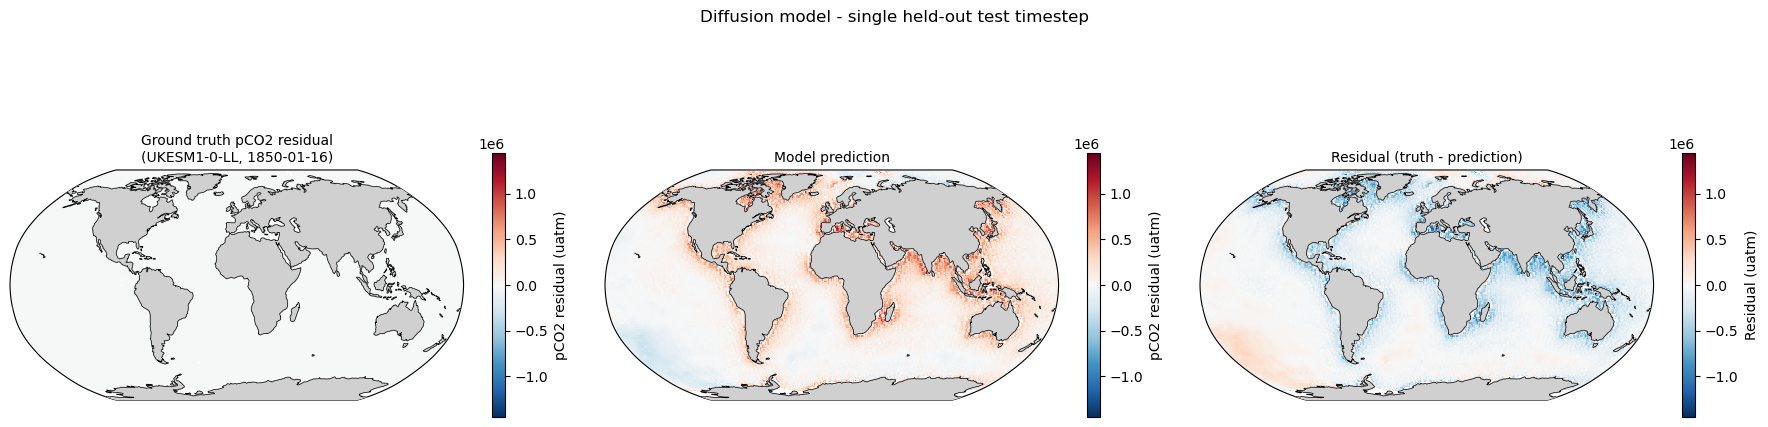

Ground truth range: -200.99 to 186.49 uatm
Prediction range:   -687340.06 to 1447015.50 uatm
Mean absolute residual: 132011.34 uatm


In [27]:
try: 
    # pick a batch from test set to visualise
    model.eval()
    with torch.no_grad():
        test_vis_idx = torch.arange(min(BATCH_SIZE, test_input_tensor.shape[0]))
        input_batch = test_input_tensor[test_vis_idx].to(DEVICE)
        target_batch = test_target_tensor[test_vis_idx].to(DEVICE)
        land_mask_batch = torch.from_numpy(test_land_mask[test_vis_idx]).bool().to(DEVICE)

    SAMPLE_IDX = 0

    pred_batch = sample(
        model=model,
        covariates=input_batch,
        land_mask=land_mask_batch,
        T=T,
        shape=target_batch.shape,
        device=DEVICE,
    ).detach() # detach to rmv from gradient graph
    pred_np = pred_batch[SAMPLE_IDX, 0].cpu().numpy()
    target_np = target_batch[SAMPLE_IDX, 0].cpu().numpy()

    pred_denorm = pred_np * target_stds[0] + target_means[0]
    target_denorm = target_np * target_stds[0] + target_means[0]

    # mask land using this sample's land mask
    sample_land_mask = test_land_mask[test_vis_idx[SAMPLE_IDX].item(), 0]
    target_masked = np.where(sample_land_mask, np.nan, target_denorm)
    pred_masked = np.where(sample_land_mask, np.nan, pred_denorm)
    residual = target_masked - pred_masked

    # get actual lat/lon and time label for this sample
    lats = test_dataset["lat"].values
    lons = test_dataset["lon"].values
    time_label = str(test_dataset.time.values[test_vis_idx[SAMPLE_IDX].item()])[:10]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={"projection": ccrs.Robinson()})

    vabs = np.nanmax(np.abs(np.concatenate([
        target_masked[np.isfinite(target_masked)],
        pred_masked[np.isfinite(pred_masked)]
    ])))
    resabs = np.nanmax(np.abs(residual[np.isfinite(residual)]))

    plot_specs = [
        (target_masked, f"Ground truth pCO2 residual\n({TEST_MODEL}, {time_label})", "RdBu_r", -vabs, vabs, "pCO2 residual (uatm)"),
        (pred_masked, "Model prediction", "RdBu_r", -vabs, vabs, "pCO2 residual (uatm)"),
        (residual, "Residual (truth - prediction)", "RdBu_r", -resabs, resabs, "Residual (uatm)")
    ]

    for ax, (data, title, cmap, vmin, vmax, cbar_label) in zip(axes, plot_specs):
        im = ax.pcolormesh(
            lons, lats, data,
            transform=ccrs.PlateCarree(),
            cmap=cmap, vmin=vmin, vmax=vmax, shading="auto"
        )
        ax.add_feature(cfeature.LAND, color="#d0d0d0", zorder=3)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
        ax.set_title(title, fontsize=10)
        plt.colorbar(im, ax=ax, shrink=0.6, label=cbar_label)

    plt.suptitle("Diffusion model - single held-out test timestep", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, "diffusion_pCO2res_map.png"), dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Ground truth range: {np.nanmin(target_masked):.2f} to {np.nanmax(target_masked):.2f} uatm")
    print(f"Prediction range:   {np.nanmin(pred_masked):.2f} to {np.nanmax(pred_masked):.2f} uatm")
    print(f"Mean absolute residual: {np.nanmean(np.abs(residual)):.2f} uatm")
    pass
except Exception as e:
    print(f"Plotting failed but model checkpoint is already saved: {e}")